In [1]:
import json
import sqlite3
import subprocess
import sys
from pathlib import Path
from decimal import Decimal
import pandas as pd
import matplotlib.pyplot as plt
from src.common import raw_hashes, read_result
from IPython.display import display, Image
BASE=Path.cwd()
def read(name): return read_result(name)
RUN_REBUILD=False
if RUN_REBUILD:
    subprocess.run([sys.executable,'-m','src.rebuild'],check=True)
data=pd.read_parquet(BASE/'clean/dataset.parquet')
display(data.head())
print('Чистых записей:',len(data))
display(data.groupby(['source','unit']).size().rename('rows').to_frame())

,business_key,source,kind,source_id,title,value,unit,stock,rating,category,year,country_code,source_url,collected_at,parser_version,status
0,books:1dfe412b8ac00530,books,book,1dfe412b8ac00530,The Black Maria,52.15,GBP,19,1,Poetry,<NA>,NaN,https://books.toscrape.com/catalogue/the-black...,2026-10-25 19:15:39.596912+00:00,lab5-html-1.0,200
1,books:2597b5a345f45e1b,books,book,2597b5a345f45e1b,The Dirty Little Secrets of Getting Your Dream...,33.34,GBP,19,4,Business,<NA>,NaN,https://books.toscrape.com/catalogue/the-dirty...,2026-10-25 19:15:41.749683+00:00,lab5-html-1.0,200
2,books:3b1c02bac2a429e6,books,book,3b1c02bac2a429e6,Scott Pilgrim's Precious Little Life (Scott Pi...,52.29,GBP,19,5,Sequential Art,<NA>,NaN,https://books.toscrape.com/catalogue/scott-pil...,2026-10-25 19:15:36.986557+00:00,lab5-html-1.0,200
3,books:4165285e1663650f,books,book,4165285e1663650f,Sapiens: A Brief History of Humankind,54.23,GBP,20,5,History,<NA>,NaN,https://books.toscrape.com/catalogue/sapiens-a...,2026-10-25 19:15:43.194488+00:00,lab5-html-1.0,200
4,books:a18a4f574854aced,books,book,a18a4f574854aced,Libertarianism for Beginners,51.33,GBP,19,2,Politics,<NA>,NaN,https://books.toscrape.com/catalogue/libertari...,2026-10-25 19:15:34.023184+00:00,lab5-html-1.0,200


Чистых записей: 661


,,rows
source,unit,
books,GBP,10
worldbank,persons,651


# Часть 1. Хранение и очистка данных

Используем сохранённые данные World Bank из третьей лабораторной и Books to Scrape из пятой. Общая схема содержит ключ, источник, название, значение, единицу и происхождение. Население и цены анализируются раздельно.

Слои хранения: raw JSONL → clean Parquet → SQLite и mart Parquet. Интернет для пересборки не нужен.

### 1.1. Исходные данные и пересборка

В raw сохраняются поля _source, _source_url, _collected_at, _parser_version и _status. Исходные значения HTML и объекты API сохранены для повторной обработки.

Отдельные 70 тестовых копий помечены _synthetic. Они показывают работу очистки и не увеличивают чистый набор. Команда python -m src.rebuild пересобирает данные и проверяет, что SHA-256 файлов raw не изменились.

In [2]:
manifest=read('raw/manifest.json')
assert raw_hashes()==manifest['sha256']
display(pd.Series({**manifest['sources'],'synthetic':manifest['synthetic']},name='Строк raw').to_frame())
proof=read('clean/rebuild_proof.json')
assert proof['raw_sha256_before']==proof['raw_sha256_after']
display(pd.Series({'Записей clean':proof['records'],'Запросов при пересборке':proof['network_requests'],'Raw не изменён':True}).to_frame('Результат'))

,Строк raw
worldbank,1085
books,20
synthetic,70


,Результат
Записей clean,661
Запросов при пересборке,0
Raw не изменён,True


### 1.2. Сравнение форматов

Один набор из 661 строки сохранён в CSV, JSONL и Parquet. Сравним размер, медиану пяти чтений и типы после загрузки. Поле code проверяет сохранение ведущих нулей.

JSONL выбран для raw, Parquet - для clean и mart. CSV удобен для просмотра и передачи таблиц, но требует явного задания типов.

In [3]:
display(pd.read_csv(BASE/'clean/format_benchmark.csv',dtype={'first_code':'string'}))
print(read('clean/format_types.json')['parquet_schema'])

,format,rows,bytes,full_read_ms,three_columns_ms,date_type,value_python_type,code_type,first_code
0,CSV,661,185099,1.059,0.750,str,float64,int64,1
1,JSONL,661,348096,6.885,7.392,"datetime64[us, UTC]",float64,int64,1
2,Parquet,661,34063,2.839,2.134,"datetime64[us, UTC]",Decimal,str,000001


business_key: large_string
source: large_string
kind: large_string
source_id: large_string
title: large_string
value: decimal128(14, 2)
unit: large_string
stock: int64
rating: int64
category: large_string
year: int64
country_code: large_string
source_url: large_string
collected_at: timestamp[us, tz=UTC]
parser_version: large_string
status: int64
code: large_string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 2040


### 1.3. Очистка и контракт

Выполняются шесть шагов: нормализация текста, бизнес-ключ, типизация, пропуски, дубликаты и бизнес-правила. Причины удалений записываются в rejects.jsonl.

Деньги хранятся как Decimal(14,2), целые с пропусками - Int64, даты - UTC. Pydantic проверяет цену, UPC, остаток, рейтинг, ISO3, год, население и соответствие единиц источнику. В модели три field_validator и один model_validator.

In [4]:
display(pd.read_csv(BASE/'clean/cleaning_protocol.csv'))
checks=read('clean/contract_checks.json')
display(pd.DataFrame(checks).drop(columns='payload'))
rejects=pd.read_json(BASE/'clean/rejects.jsonl',lines=True)
display(rejects.groupby(['stage','reason']).size().rename('count').to_frame())

,step,before,after,changed,removed,note
0,1. Нормализация текста,1175,1175,9,0,"NFKC, NBSP, zero-width, пробелы"
1,2. Бизнес-ключ,1175,1175,1175,0,UPC / ISO3 + показатель + год; URL без трекинга
2,3. Типизация,1175,1175,1175,0,"Decimal(14,2), целые, datetime с UTC; ошибки н..."
3,4. Пропуски,1175,1148,0,27,Обязательные → rejects; необязательные → NULL
4,5. Дубликаты,1148,671,0,477,"Свежая запись; полные, по ключу, нормализованн..."
5,6. Бизнес-правила и контракт,671,661,0,10,Цена > 0 и ≤ 10000; UPC; рейтинг 1–5; остаток ...


,check,result,field,message
0,Отрицательная цена,отклонено,"('value',)",Input should be greater than 0
1,Пустое название,отклонено,"('title',)",String should have at least 2 characters
2,Рейтинг 8,отклонено,"('rating',)",Input should be less than or equal to 5
3,Остаток -2,отклонено,"('stock',)",Input should be greater than or equal to 0
4,Дата без зоны,отклонено,"('collected_at',)","Value error, Дата должна содержать часовой пояс"
5,Чужой URL,отклонено,"('source_url',)","Value error, Нужен HTTPS URL одного из двух ис..."
6,Валюта книги,отклонено,(),"Value error, Книга: источник books, GBP, остат..."


count
stage                 reason                                                   
4. Пропуски           обязательное поле пусто или не удалось разобрат...     27
5. Дубликаты          дубль бизнес-ключа                                    449
                      полный дубль                                           20
                      почти-дубль                                             8
6. Правила и контракт Input should be greater than 0                          5
                      Input should be greater than or equal to 0              5

### 1.4. База данных и повторная загрузка

SQLite использует бизнес-ключ по UPC или ISO3, показателю и году. Деньги записываются целым числом сотых: 51,77 GBP соответствует 5177. Загрузка выполняется пакетным UPSERT.

В warehouse.db находятся очищенные данные. В отдельной idempotency_demo.db выполнены три загрузки: исходная, повторная и с изменением двух цен на 1 GBP. updated_at и история меняются только при изменении данных.

In [5]:
display(pd.DataFrame(read('clean/idempotency.json')))
display(pd.DataFrame(read('clean/database_checks.json')))
with sqlite3.connect(BASE/'db/warehouse.db') as connection:
    display(pd.read_sql_query('SELECT source,unit,count(*) AS rows FROM records GROUP BY source,unit',connection))
    print('Строк rejects в БД:',connection.execute('SELECT count(*) FROM rejects').fetchone()[0])
display(pd.read_csv(BASE/'clean/history_demo.csv')[['business_key','version_at','value_minor']])

,run,rows,changed,history_rows,loaded_at
0,1. Исходный,661,661,661,2026-10-25T21:35:48.677588+00:00
1,2. Повторный,661,0,661,2026-10-25T21:35:48.699309+00:00
2,3. Две тестовые цены,661,2,663,2026-10-25T21:35:48.712544+00:00


,check,result,message
0,CHECK отрицательного значения,отклонено,CHECK constraint failed: typeof(value_minor)='...
1,Дубликат ключа,отклонено,"UNIQUE constraint failed: records.source, reco..."


,source,unit,rows
0,books,GBP,10
1,worldbank,persons,651


Строк rejects в БД: 955


,business_key,version_at,value_minor
0,books:1dfe412b8ac00530,2026-10-25T21:35:48.677588+00:00,5215
1,books:1dfe412b8ac00530,2026-10-25T21:35:48.712544+00:00,5315
2,books:2597b5a345f45e1b,2026-10-25T21:35:48.677588+00:00,3334
3,books:2597b5a345f45e1b,2026-10-25T21:35:48.712544+00:00,3434


### 1.5. Метрики качества

Рассчитываются девять метрик с зелёным, жёлтым и красным порогами. Контракт проверяется до удаления повторов. Валидность и доля дубликатов оцениваются отдельно.

Красный статус останавливает загрузку mart. В сохранённом результате статус жёлтый из-за повторных ответов API; ключи чистой таблицы уникальны.

In [6]:
quality=read('clean/quality.json')
display(pd.DataFrame(quality['metrics']))
print('Итог:',quality['status'],'Все удаления от raw:',round(100*quality['total_removed_fraction'],2),'%')
print('Проверка красного статуса:',read('clean/red_gate_demo.json'))

,metric,value,green,yellow,direction,status,reason
0,Полнота обязательных,1.000000,1.00,0.99,>=,green,Обязательные поля нужны всем представлениям
1,Полнота необязательных,1.000000,0.95,0.80,>=,green,"Категория оценивается только у книг, к API неп..."
2,Уникальность ключей,1.000000,1.00,0.99,>=,green,Дубли искажают агрегаты
3,Валидность от raw,0.961702,0.95,0.90,>=,green,Контракт проверяется до удаления повторов; пов...
4,Доля невалидных строк,0.031489,0.05,0.10,<=,green,Отбраковка по типам/правилам; удаления повторо...
5,Доля удаления повторов,0.405957,0.10,0.50,<=,yellow,"Повторная доставка допустима, но более 10% тре..."
6,Согласованность правил,1.000000,1.00,0.99,>=,green,"Ключ, единицы и предметные диапазоны должны со..."
7,"Возраст данных, дней",0.256877,7.00,30.00,<=,green,"Возраст с момента получения, год наблюдения хр..."
8,Изменение объёма,0.000000,0.10,0.20,<=,green,Падение более 20% требует остановки


Итог: yellow Все удаления от raw: 43.74 %
Проверка красного статуса: {'blocked': True, 'message': 'Загрузка mart остановлена: Полнота обязательных'}


### 1.6. Витрины и графики

Созданы три SQL-представления и Parquet-выгрузки: сводка по источникам, население по годам и десять самых дорогих книг. Снимки разделены по дате получения. Прочитаем одну партицию и построим два графика.

by_source


,source,unit,records,min_value_minor,max_value_minor
0,books,GBP,10,1746,5423
1,worldbank,persons,651,999200,142542321200


population_by_year


,year,countries,population_total
0,2020,217,7830279316
1,2021,217,7896080486
2,2022,217,7965363923


top_books


,title,category,value_minor,rating
0,Sapiens: A Brief History of Humankind,History,5423,5
1,Scott Pilgrim's Precious Little Life (Scott Pi...,Sequential Art,5229,5
2,The Black Maria,Poetry,5215,1
3,Libertarianism for Beginners,Politics,5133,2
4,The Dirty Little Secrets of Getting Your Dream...,Business,3334,4
5,Olio,Poetry,2388,1
6,The Requiem Red,Young Adult,2265,1
7,The Boys in the Boat: Nine Americans and Their...,Default,2260,4
8,The Coming Woman: A Novel Based on the Life of...,Default,1793,3
9,Set Me Free,Young Adult,1746,5


Одна партиция: {'file': 'mart/snapshots/dt=2026-10-25/part-000.parquet', 'rows_read': 661}


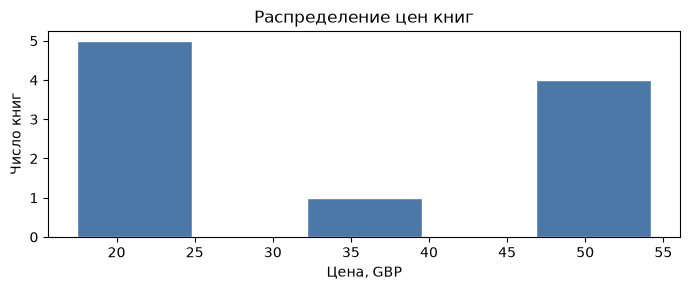

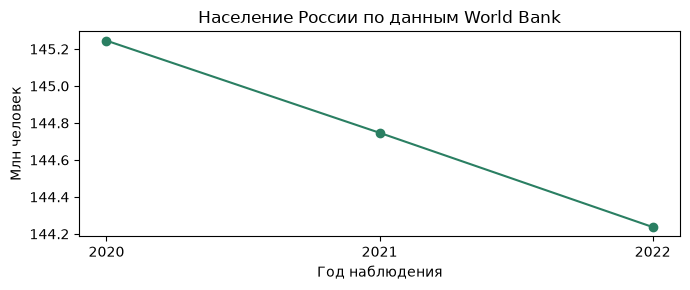

In [7]:
for name in ['by_source','population_by_year','top_books']:
    print(name)
    display(pd.read_parquet(BASE/f'mart/views/{name}.parquet'))
partition=read('mart/partition_read.json')
print('Одна партиция:',partition)
assert len(pd.read_parquet(BASE/partition['file']))==partition['rows_read']
plt.rcParams['font.family']='DejaVu Sans'
fig,ax=plt.subplots(figsize=(7,3))
books=data[data.kind=='book']
ax.hist(books.value.astype(float),bins=5,color='#4c78a8',edgecolor='white')
ax.set(title='Распределение цен книг',xlabel='Цена, GBP',ylabel='Число книг')
fig.tight_layout();plt.show()
rus=data[data.country_code=='RUS'].sort_values('year')
fig,ax=plt.subplots(figsize=(7,3))
ax.plot(rus.year,rus.value.astype(float)/1e6,marker='o',color='#2a7f62')
ax.set(title='Население России по данным World Bank',xlabel='Год наблюдения',ylabel='Млн человек',xticks=rus.year)
fig.tight_layout();plt.show()

# Часть 2. Обработка данных в n8n

Workflow читает CSV, нормализует поля, удаляет повторные ключи, разделяет корректные и ошибочные строки и сохраняет две таблицы. Настроено расписание на 09:00 по Перми; автоматический запуск выключен до публикации.

| Этап | Python | n8n |
|---|---|---|
| Нормализация | Шесть шагов очистки | Code: ключ, текст, сумма, источник, URL |
| Дубликаты | Ключ и выбор свежей записи | Remove Duplicates |
| Проверки | Pydantic и бизнес-правила | Code и IF |
| Отбраковка | rejects.jsonl и таблица SQLite | Отдельный CSV |
| Загрузка | UPSERT в SQLite | CSV; файловый узел не поддерживает SQL UPSERT |
| История и светофор | Снимки изменений и gate_mart | В этом workflow не реализованы |

In [8]:
display(pd.Series(read('nocode/execution_summary.json')).drop('nodes').to_frame('n8n'))
nocode=pd.read_csv(BASE/'nocode/nocode_result.csv')
assert len(nocode)>=30 and not nocode.duplicated('business_key').any()
display(nocode.head())
display(pd.read_csv(BASE/'nocode/rejects.csv'))

,n8n
status,success
started_at,2026-10-25T21:44:12.496Z
stopped_at,2026-10-25T21:44:13.344Z
seconds,0.848
records,40
rejects,4


,business_key,title,source,value,unit,source_url,valid,reason
0,books:1dfe412b8ac00530,The Black Maria,books,52.15,GBP,https://books.toscrape.com/catalogue/the-black...,True,NaN
1,books:2597b5a345f45e1b,The Dirty Little Secrets of Getting Your Dream...,books,33.34,GBP,https://books.toscrape.com/catalogue/the-dirty...,True,NaN
2,books:3b1c02bac2a429e6,Scott Pilgrim's Precious Little Life (Scott Pi...,books,52.29,GBP,https://books.toscrape.com/catalogue/scott-pil...,True,NaN
3,books:4165285e1663650f,Sapiens: A Brief History of Humankind,books,54.23,GBP,https://books.toscrape.com/catalogue/sapiens-a...,True,NaN
4,books:a18a4f574854aced,Libertarianism for Beginners,books,51.33,GBP,https://books.toscrape.com/catalogue/libertari...,True,NaN


,business_key,title,source,value,unit,source_url,valid,reason
0,invalid:0,NaN,books,52.15,GBP,https://books.toscrape.com/catalogue/the-black...,False,"Пустое поле, неверное число или единица"
1,invalid:1,The Black Maria,books,-1,GBP,https://books.toscrape.com/catalogue/the-black...,False,"Пустое поле, неверное число или единица"
2,invalid:2,The Black Maria,books,abc,GBP,https://books.toscrape.com/catalogue/the-black...,False,"Пустое поле, неверное число или единица"
3,invalid:3,The Black Maria,books,52.15,XXX,https://books.toscrape.com/catalogue/the-black...,False,"Пустое поле, неверное число или единица"


### 2.1. Схема и успешный запуск

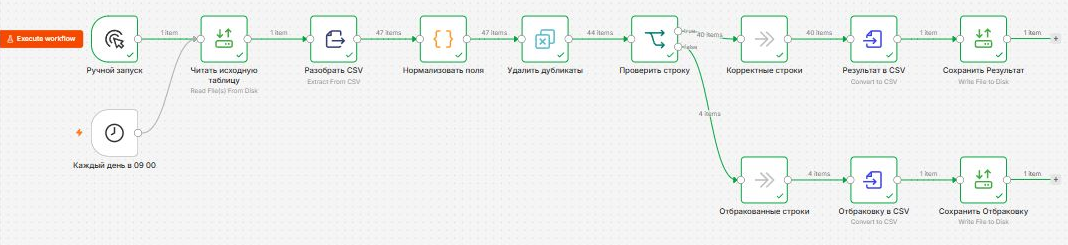

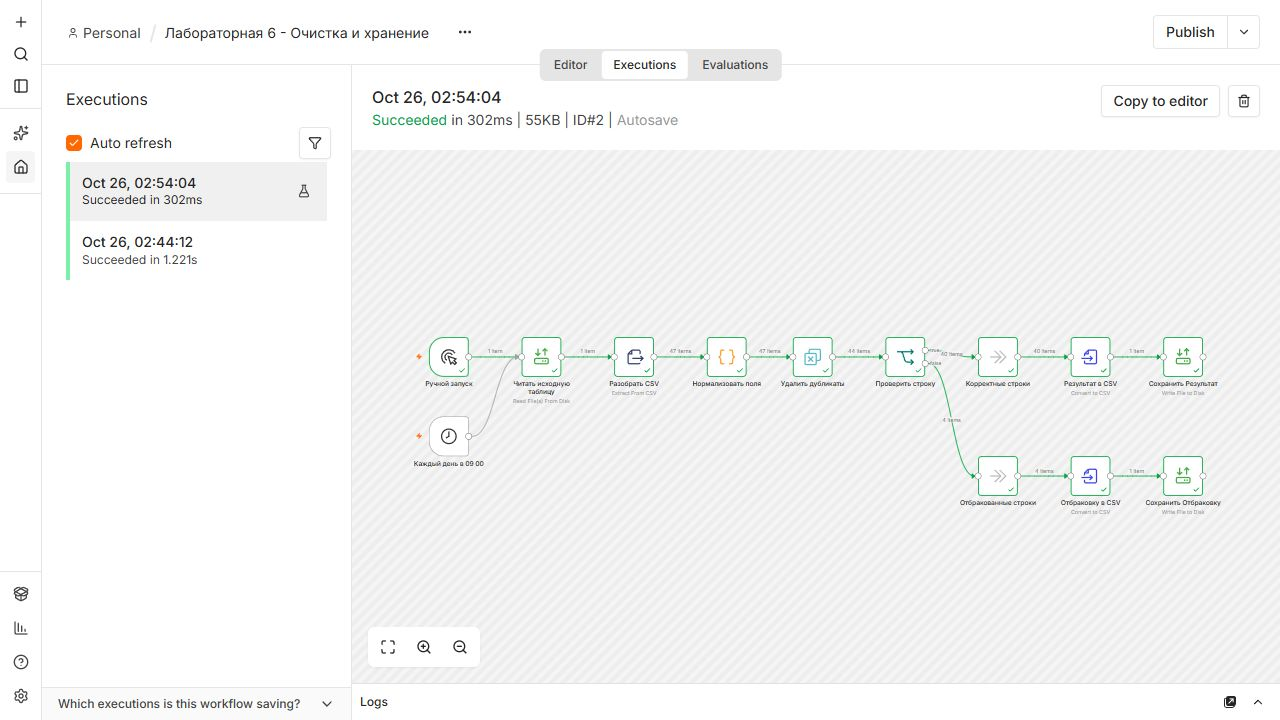

In [9]:
for name in ["screenshot_workflow.png", "screenshot_success.png"]:
    display(Image(filename=str(BASE / "nocode" / name), width=1000))

# Итоговый вывод

Из двух источников получен чистый набор из 661 строки. Очистка, контракт, UPSERT, история и витрины воспроизводятся из raw без обращения к сайтам. Повторная загрузка не меняет данные, изменение двух цен отражается только в двух записях.

n8n сохранил 40 корректных и 4 ошибочные строки. Он подходит для простой обработки таблицы. Полный контракт, история и контроль качества реализованы на Python.

### Источники
- [World Bank API](https://datahelpdesk.worldbank.org/knowledgebase/articles/889392-about-the-indicators-api-documentation)
- [Books to Scrape](https://books.toscrape.com/)
- [Pydantic](https://docs.pydantic.dev/latest/concepts/validators/)
- [SQLite UPSERT](https://sqlite.org/lang_upsert.html)
- [Apache Parquet](https://parquet.apache.org/)